# Demanda y Oferta Energética — Bangladesh

# Práctica: Regresión Lineal

- Asignatura: Machine Learning
- Nombre: Andrea Georgina Rodríguez Pacheco
- Matrícula: 395699
- Dataset: PGCB Hourly Generation Dataset (Bangladesh)
- Variables objetivo: `demand_mw` (demanda) y `generation_mw` (oferta)

In [31]:
pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_squared_error

# 1. Carga del conjunto de datos

Utilice el conjunto PGCB Hourly Generation Dataset (Bangladesh), disponible en el UCI Machine Learning Repository.

El conjunto contiene información horaria de generación, demanda, fuentes de energía e importaciones de la red eléctrica de Bangladesh (Power Grid Company of Bangladesh).

In [33]:
import zipfile

zip_path = "../pgcb+hourly+generation+dataset+(bangladesh).zip"

with zipfile.ZipFile(zip_path) as z:
    X = pd.read_excel(z.open("PGCB_date_power_demand.xlsx"))

# Demanda y oferta (generación) horaria en MW
TARGETS = ["demand_mw", "generation_mw"]

# print(X.head(5))
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92650 entries, 0 to 92649
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   datetime              92650 non-null  datetime64[ns]
 1   generation_mw         92650 non-null  float64       
 2   demand_mw             92650 non-null  int64         
 3   load_shedding         92650 non-null  int64         
 4   gas                   92650 non-null  int64         
 5   liquid_fuel           92650 non-null  int64         
 6   coal                  92650 non-null  int64         
 7   hydro                 92650 non-null  int64         
 8   solar                 70517 non-null  float64       
 9   wind                  18676 non-null  float64       
 10  india_bheramara_hvdc  92650 non-null  int64         
 11  india_tripura         92650 non-null  int64         
 12  india_adani           7338 non-null   float64       
 13  nepal           

### Preguntas
**¿Cuál es el objetivo general del problema?**
Identificar los puntos críticos donde la demanda excede a la capacidad de suministro y puede producirse un desprendimiento de carga.
**¿Qué representa cada instancia del dataset?**
Las métricas obteneidas por hora 
**¿Cuál es la variable que se desea predecir?**
Demand_mw
**¿Por qué este problema corresponde a aprendizaje supervisado?**
Buscamos predecir el volumen de demanda de energía en un determinado momento, a partir de datos donde ese dato ya es conocido.
**¿Por qué corresponde específicamente a un problema de regresión**
Porque buscamos un valor continuo no una categoría.

## 2. Inspección inicial del dataset
Antes de dividir los datos o realizar el análisis exploratorio, realizaremos una inspección estructural inicial.

En esta etapa deberá identificar:

* dimensiones del dataset
* nombres de las columnas
* tipos de datos
* primeras observaciones
* valores faltantes
* registros duplicados
* posibles problemas de formato o codificación.

In [34]:
# Estructura genérica del dataset
length = len("Dimensiones del dataset")
border = "*" * (length + 4)

print(border)
print(f"* Dimensiones de mi dataset *")
print("Filas:", X.shape[0])
print("Columnas:", X.shape[1])
print(border)
print(f"* Columnas *")
print(X.columns.to_list())
print(border)
print(f"* Tipos de datos *")
print(X.dtypes)
print(border)

***************************
* Dimensiones de mi dataset *
Filas: 92650
Columnas: 15
***************************
* Columnas *
['datetime', 'generation_mw', 'demand_mw', 'load_shedding', 'gas', 'liquid_fuel', 'coal', 'hydro', 'solar', 'wind', 'india_bheramara_hvdc', 'india_tripura', 'india_adani', 'nepal', 'remarks']
***************************
* Tipos de datos *
datetime                datetime64[ns]
generation_mw                  float64
demand_mw                        int64
load_shedding                    int64
gas                              int64
liquid_fuel                      int64
coal                             int64
hydro                            int64
solar                          float64
wind                           float64
india_bheramara_hvdc             int64
india_tripura                    int64
india_adani                    float64
nepal                          float64
remarks                         object
dtype: object
***************************


In [35]:
print(f"* Valores faltantes *")
print(X.isnull().sum())
print(border)
print(f"* Valores duplicados *")
print(X.duplicated().sum())
print(border)
print(f"* Rango *")
print(X[TARGETS].agg(["min", "max"]))
print(border)
print(f"* Vista previa del dataset *")
print(X.head().to_string(index=False))
print(border)

print(f"* Resumen estadístico (variables numéricas) *")
print(X.describe().round(2).to_string())
print(border)

* Valores faltantes *
datetime                    0
generation_mw               0
demand_mw                   0
load_shedding               0
gas                         0
liquid_fuel                 0
coal                        0
hydro                       0
solar                   22133
wind                    73974
india_bheramara_hvdc        0
india_tripura               0
india_adani             85312
nepal                   87299
remarks                 86257
dtype: int64
***************************
* Valores duplicados *
160
***************************
* Rango *
     demand_mw  generation_mw
min          6           73.0
max     156050     64526500.0
***************************
* Vista previa del dataset *
           datetime  generation_mw  demand_mw  load_shedding  gas  liquid_fuel  coal  hydro  solar  wind  india_bheramara_hvdc  india_tripura  india_adani  nepal      remarks
2015-04-19 22:00:00         6323.0       6323              0    0            0     0      0    NaN  

### Preguntas
**¿Cuántas instancias contiene el dataset?**

92659

**¿Cuántas columnas contiene?**
15

**¿Cuáles son los nombres de las variables?**

datetime, generation_mw, demand_mw, load_shedding, gas, liquid_fuel, coal, hydro, solar, wind, india_bheramara_hvdc,india_tripura, india_adani, nepal, remarks   

**¿Qué variables son numéricas?**
generation_mw
demand_mw
load_shedding
gas
liquid_fuel
coal
hydro
solar
wind
india_bheramara_hvdc
india_tripura
india_adani
nepal

**¿Qué variables son categóricas?**
remarks

**¿Existen valores faltantes? ¿En qué variables?**

solar                   22133
wind                    73974
india_adani             85312
nepal                   87299

**¿Existen registros duplicados? ¿Cuántos?**
160

**¿Cuál es el tipo de dato de datetime?**
datetime

**¿Es conveniente utilizar datetime directamente como entrada del modelo?**

No, habría que aplicarle alguna transformación de tipo binaria como one hot encoding o bien codificación cíclica de las horas.


**¿Detecta algún problema evidente de formato, codificación o tipo de dato?**

Remarks, es una variable categórica con muy poca varianza

**¿Las variables objetivo se encuentran en un rango razonable para representar la demanda y la generación en MW?**

## 3. Separación de X e y
Separe las características y las variables objetivo.

X = variables predictoras

y = `demand_mw`, `generation_mw`

### Variables excluidas de X
Solo se conservan variables conocidas **antes** de la hora que se desea predecir:

- `load_shedding` ≈ `demand_mw` − `generation_mw`: usarla sería reconstruir la respuesta a partir de su propia definición.
- `gas`, `liquid_fuel`, `coal`, `hydro`, `solar`, `wind`, `india_*`, `nepal`: su suma es la generación de esa misma hora (correlación ≈ 0.995), por lo que tampoco se conocen de antemano.

La información histórica de demanda y oferta se incorpora en Feature Engineering mediante valores rezagados (horas anteriores).

In [36]:
# Eliminación de registros duplicados: un mismo registro en Train y en Test sería fuga de información
X = X.drop_duplicates().reset_index(drop=True)

# Orden cronológico (el archivo viene en orden descendente) y una sola fila por marca de tiempo
X = X.sort_values("datetime").drop_duplicates(subset="datetime", keep="last").reset_index(drop=True)

# Eliminación de valores físicamente imposibles (errores de captura, p. ej. generation_mw = 64,526,500).
# Los límites son fijos, basados en la capacidad de la red de Bangladesh (pico histórico < 17,000 MW),
# no se calculan a partir de los datos, por lo que pueden aplicarse antes de la partición sin fuga de información.
max_mw = {
    "generation_mw": 20000, "demand_mw": 20000, "load_shedding": 5000,
    "gas": 15000, "liquid_fuel": 10000, "coal": 10000, "hydro": 1000,
    "india_bheramara_hvdc": 2000, "india_tripura": 500, "india_adani": 3000,
}
invalid = np.zeros(len(X), dtype=bool)
for col, limit in max_mw.items():
    invalid |= X[col] > limit
print("Registros con valores imposibles eliminados:", invalid.sum())
X = X[~invalid].reset_index(drop=True)

# Comprobación: la generación es la suma de las fuentes de esa misma hora
sources = ["gas", "liquid_fuel", "coal", "hydro", "solar", "wind",
           "india_bheramara_hvdc", "india_tripura", "india_adani", "nepal"]
print("Correlación generation_mw vs suma de fuentes:",
      round(np.corrcoef(X["generation_mw"], X[sources].fillna(0).sum(axis=1))[0, 1], 4))

X_var = X[["datetime", "remarks"]].copy()
y_var = X[TARGETS].copy()
print("X:", X_var.shape, "| y:", y_var.shape)

Registros con valores imposibles eliminados: 168
Correlación generation_mw vs suma de fuentes: 0.995
X: (92050, 2) | y: (92050, 2)


### Preguntas

**¿Cuántas características contiene inicialmente X?**

**¿Qué dimensión tiene X?**

**¿Qué dimensión tiene y?**

**¿Qué representa cada fila de X?**

**¿Qué representa cada columna de X?**

**¿Verificó que las variables objetivo no se encuentren incluidas dentro de X?**

**¿Existe alguna característica que requiera tratamiento especial posteriormente?**

# 4. Partición Train/Test temporal
Realice una partición **cronológica**:

80% más antiguo → Train

20% más reciente → Test

A partir de este momento, el conjunto Test deberá permanecer aislado hasta la evaluación final.

### Restricción de eventos futuros
Los registros forman una serie de tiempo: observaciones consecutivas están fuertemente autocorrelacionadas. Con una partición aleatoria:

- El modelo se entrenaría con registros **posteriores** a los de Test, es decir, usaría información del futuro para "predecir" el pasado.
- Cada registro de Test tendría casi siempre un vecino inmediato (la hora anterior o siguiente) en Train, por lo que el error de Test resultaría artificialmente bajo.

Por ello la partición se realiza con `shuffle=False` sobre los datos ordenados por `datetime`: todo Train es anterior a todo Test, igual que ocurriría al usar el modelo en producción.

In [37]:
train_set_x, test_set_x, train_set_y, test_set_y = train_test_split(
    X_var, y_var, test_size=0.2, shuffle=False
)
print(f"* Dimensiones de conjunto de entrenamiento X*")
print("Filas:", train_set_x.shape[0])
print("Columnas:", train_set_x.shape[1])
print(f"* Dimensiones de conjunto de prueba X*")
print("Filas:", test_set_x.shape[0])
print("Columnas:", test_set_x.shape[1])

print(f"* Dimensiones de conjunto de entrenamiento y *")
print("Filas:", train_set_y.shape[0])
print(f"* Dimensiones de conjunto de prueba y*")
print("Filas:", test_set_y.shape[0])

# Restricción de eventos futuros: todo Train debe ser anterior a todo Test
print(f"* Periodo de cada conjunto *")
print("Train:", train_set_x["datetime"].min(), "→", train_set_x["datetime"].max())
print("Test: ", test_set_x["datetime"].min(), "→", test_set_x["datetime"].max())
assert train_set_x["datetime"].max() < test_set_x["datetime"].min()

# Diagnóstico: nivel promedio de demanda y oferta en cada periodo
print(f"* Promedio de las variables objetivo (Train vs Test) *")
print(pd.DataFrame({"Train": train_set_y.mean(), "Test": test_set_y.mean()}).round(1))

* Dimensiones de conjunto de entrenamiento X*
Filas: 73640
Columnas: 2
* Dimensiones de conjunto de prueba X*
Filas: 18410
Columnas: 2
* Dimensiones de conjunto de entrenamiento y *
Filas: 73640
* Dimensiones de conjunto de prueba y*
Filas: 18410
* Periodo de cada conjunto *
Train: 2015-04-19 00:00:00 → 2023-06-09 16:00:00
Test:  2023-06-09 17:00:00 → 2025-06-17 12:00:00
* Promedio de las variables objetivo (Train vs Test) *
                Train     Test
demand_mw      8161.6  11438.2
generation_mw  8116.0  11230.5


### Preguntas

**¿Cuántas instancias quedaron en Train?**
73774

**¿Cuántas instancias quedaron en Test?**
18444

**¿Por qué se realiza la partición antes del EDA?**
Para evitar que 
**¿Por qué el EDA detallado debe realizarse únicamente sobre Train?**
Para evitar sesgos. a partir de las tendencias identificadas a futuro, sobretodo en un problema de series temporales

**¿Qué tipo de fuga de información podría ocurrir si utilizamos Test para tomar decisiones de modelado?**
Podríamos estar "prediciendo" eventos de load shedding futuros que ya han sido aprendidos en el modelo, quizá podría tener buen rendimiento en training pero será inútil con información desconocida.

**¿Por qué Test no debe utilizarse para seleccionar hiperparámetros?**
Para evitar seleccionar hiperparámetros en el modelo y evitar data leakage.

**¿Qué representa conceptualmente el conjunto Test?**
Datos futuros que nunca han sido vistos por el modelo

## 5. Análisis Exploratorio de Datos — EDA

### 5.1 Distribución de las variables objetivo
Analice `demand_mw` y `generation_mw`.

### Preguntas

**¿Las distribuciones son aproximadamente simétricas?**

**¿Existe sesgo hacia valores bajos o altos?**

**¿Existen valores inusualmente altos o bajos?**

**¿Estos valores podrían representar errores o situaciones reales?**

**¿En qué rango se encuentra la mayor concentración de instancias?**

**¿Cómo podría afectar esta distribución a las métricas de error?**

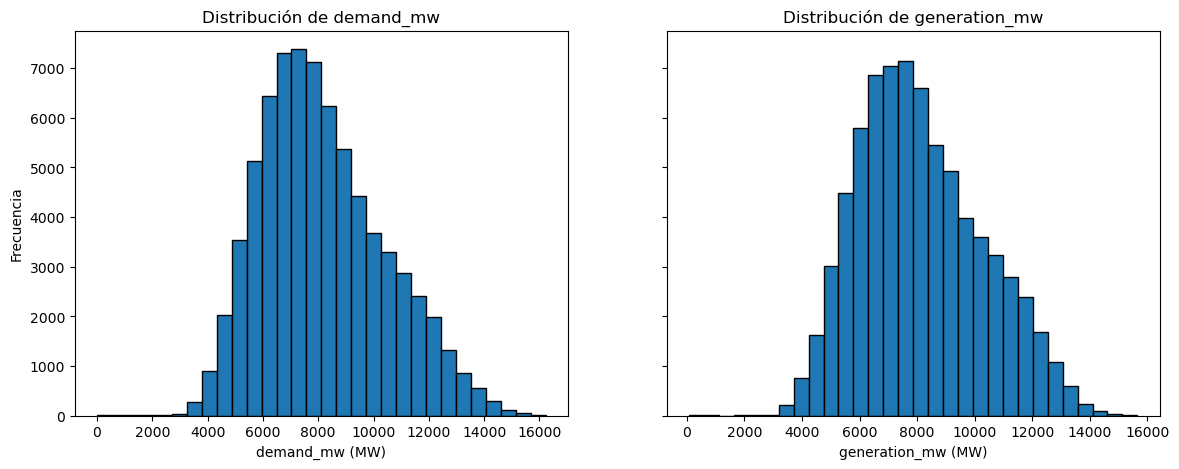

In [38]:
# Distribución de las variables objetivo
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, target in zip(axes, TARGETS):
    ax.hist(train_set_y[target], bins=30, edgecolor='black')
    ax.set_title(f'Distribución de {target}')
    ax.set_xlabel(f'{target} (MW)')
axes[0].set_ylabel('Frecuencia')
plt.show()

### 5.2 Hora del día, demanda y oferta
Analice la relación entre la hora del día y las variables objetivo.

### Preguntas

**¿La relación entre la hora y la demanda/oferta parece lineal?**

**¿A qué horas aparecen los principales picos?**

**¿Los picos podrían relacionarse con horarios de mayor consumo?**

**¿Qué ocurre durante la madrugada?**

**¿Una regresión lineal utilizando la hora directamente como una variable numérica podría capturar adecuadamente este patrón?**

**¿Qué transformación de la hora podría ayudar a representar mejor su naturaleza periódica?**

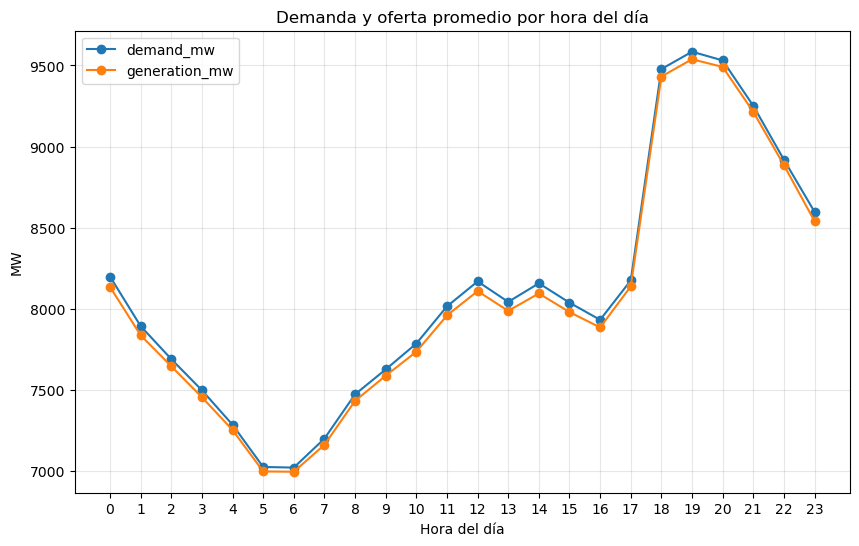

In [39]:
# Demanda y oferta promedio por hora del día
hourly = train_set_y.groupby(train_set_x['datetime'].dt.hour).mean()

plt.figure(figsize=(10, 6))
for target in TARGETS:
    plt.plot(hourly.index, hourly[target], marker='o', label=target)
plt.title('Demanda y oferta promedio por hora del día')
plt.xlabel('Hora del día')
plt.ylabel('MW')
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 5.3 Tendencia en el tiempo
Analice la evolución de la demanda y la oferta a lo largo de los años.

### Preguntas

**¿Existe una tendencia creciente o decreciente?**

**¿La demanda y la oferta evolucionan de la misma forma?**

**¿En qué periodos la demanda supera a la oferta?**

**¿Cómo afecta esta tendencia a una partición temporal Train/Test?**

**¿Qué información del pasado podría ayudar a predecir el nivel actual de demanda y oferta?**

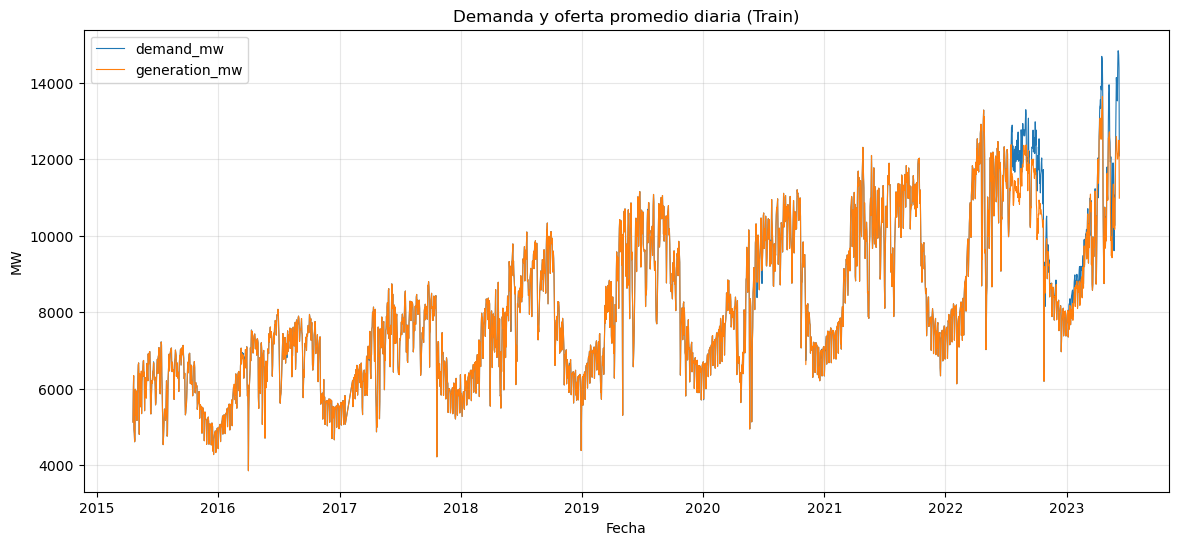

In [40]:
# Promedio diario de demanda y oferta (solo Train)
daily = train_set_y.groupby(train_set_x['datetime'].dt.date).mean()

plt.figure(figsize=(14, 6))
for target in TARGETS:
    plt.plot(daily.index, daily[target], linewidth=0.8, label=target)
plt.title('Demanda y oferta promedio diaria (Train)')
plt.xlabel('Fecha')
plt.ylabel('MW')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 5.4 Relación entre demanda y oferta
Analice la relación entre `demand_mw` y `generation_mw`.

### Preguntas

**¿Qué patrón observa?**

**¿La relación parece lineal?**

**¿Qué representan los puntos por debajo de la diagonal?**

**¿Por qué no se puede utilizar una de las variables objetivo como característica para predecir la otra?**

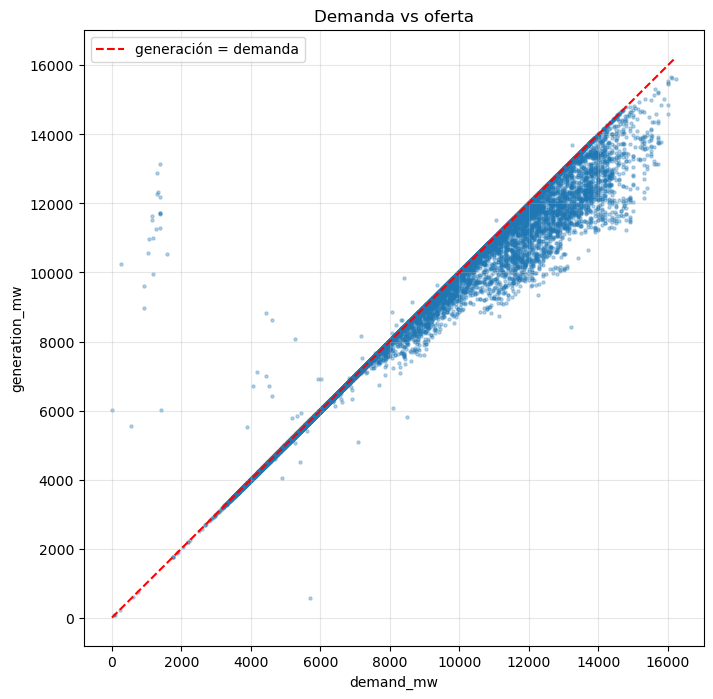

In [41]:
plt.figure(figsize=(8, 8))
plt.scatter(train_set_y['demand_mw'], train_set_y['generation_mw'], alpha=0.3, s=5)
lims = [train_set_y.min().min(), train_set_y.max().max()]
plt.plot(lims, lims, 'r--', label='generación = demanda')
plt.title('Demanda vs oferta')
plt.xlabel('demand_mw')
plt.ylabel('generation_mw')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 5.5 Mes del año
Analice la demanda y la oferta de acuerdo con el mes.

### Preguntas

**¿En qué mes existe mayor demanda promedio?**

**¿En cuál existe menor?**

**¿Las diferencias parecen relevantes?**

**¿El mes debería tratarse como una variable numérica o categórica?**

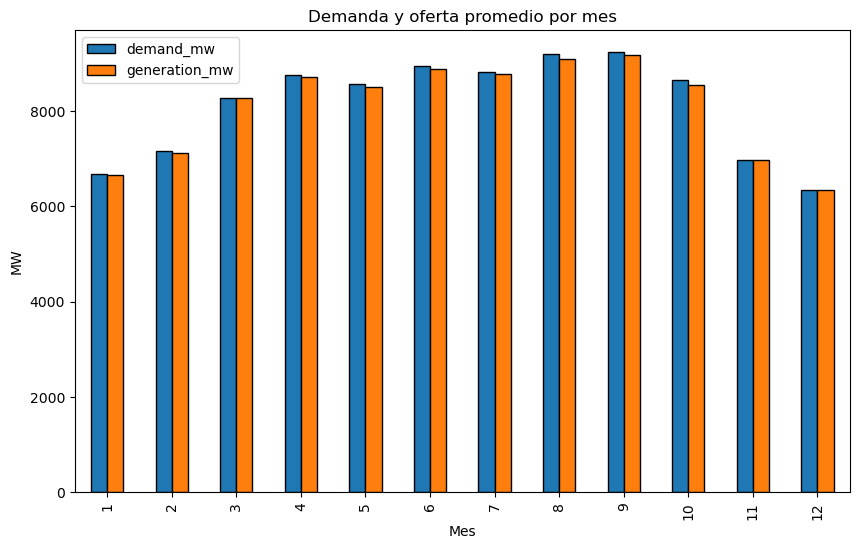

In [42]:
# Demanda y oferta promedio por mes
monthly = train_set_y.groupby(train_set_x['datetime'].dt.month).mean()

monthly.plot(kind='bar', figsize=(10, 6), edgecolor='black')
plt.title('Demanda y oferta promedio por mes')
plt.xlabel('Mes')
plt.ylabel('MW')
plt.show()

## 5.6 Correlaciones
Analice las correlaciones de Pearson entre las variables numéricas del conjunto original (solo Train) y las variables objetivo.

### Preguntas

**¿Qué variable presenta mayor correlación positiva con la demanda y con la oferta?**

**¿Cuál presenta mayor correlación negativa?**

**¿Existen variables con r ≈ 0?**

**¿Un valor r ≈ 0 significa necesariamente que una variable no es útil para predecir?**

**¿Por qué Pearson puede no detectar una relación no lineal?**

**¿Es adecuado seleccionar características únicamente con base en su correlación con la variable objetivo? ¿Por qué no se utilizan las fuentes de generación aunque su correlación sea alta?**

In [43]:
# Correlación de las columnas originales (solo registros de Train) con las variables objetivo
train_original = X.loc[train_set_x.index].select_dtypes(include=np.number)

corr_with_targets = train_original.corr(method="pearson")[TARGETS].drop(TARGETS)
corr_with_targets.sort_values("demand_mw", ascending=False)

,demand_mw,generation_mw
liquid_fuel,0.819653,0.829728
india_bheramara_hvdc,0.730819,0.733559
india_tripura,0.715945,0.723725
gas,0.712584,0.731846
coal,0.596897,0.571287
load_shedding,0.367749,0.269389
solar,0.172648,0.149654
hydro,0.034477,0.038512
wind,-0.167555,-0.108134
india_adani,NaN,NaN


## 6. Feature Engineering
A partir de los resultados obtenidos durante el EDA, proponga y justifique al menos dos nuevas características.

Puede considerar, entre otras:

- Month
- DayOfWeek
- IsWeekend
- transformaciones cíclicas de Hour
- valores rezagados (lags) de demanda y oferta
- interacciones entre variables

### Importante
Conserve la variable datetime, o una copia del dataset original, ya que será necesaria posteriormente para realizar el experimento con partición temporal.

Las transformaciones diseñadas deberán poder aplicarse de manera reproducible tanto a Train como a nuevas observaciones.

### Valores rezagados
Para cada registro se busca la demanda y la oferta observadas **24 horas antes** (mismo horario del día anterior) y **168 horas antes** (misma hora de la semana anterior). Solo se utilizan valores del pasado, que ya son conocidos al momento de predecir; si no existe registro a esa hora, el valor queda vacío y se imputa en el preprocesamiento.

In [44]:
# Nueva característica: Hora cíclica
def add_hour_cyclical_features(df):
    df = df.copy()
    df["Hour"] = df["datetime"].dt.hour
    hour_norm = df["Hour"] / 24.0
    df["Hour_sin"] = np.sin(2 * np.pi * hour_norm)
    df["Hour_cos"] = np.cos(2 * np.pi * hour_norm)
    return df


train_set_x = add_hour_cyclical_features(train_set_x)
test_set_x = add_hour_cyclical_features(test_set_x)

print(train_set_x[["datetime", "Hour", "Hour_sin", "Hour_cos"]].head())

             datetime  Hour  Hour_sin  Hour_cos
0 2015-04-19 00:00:00     0  0.000000  1.000000
1 2015-04-19 01:00:00     1  0.258819  0.965926
2 2015-04-19 02:00:00     2  0.500000  0.866025
3 2015-04-19 03:00:00     3  0.707107  0.707107
4 2015-04-19 04:00:00     4  0.866025  0.500000


In [45]:
def add_day_of_week_features(df):
    df = df.copy()

    # Convert datetime if it is still stored as text
    if df["datetime"].dtype == object:
        df["datetime"] = pd.to_datetime(df["datetime"])

    # New feature: day of the week (Monday=0 ... Sunday=6)
    df["DayOfWeek"] = df["datetime"].dt.dayofweek

    # In Bangladesh the weekend is Friday and Saturday
    df["IsWeekend"] = df["DayOfWeek"].isin([4, 5]).astype(int)

    # Month as a category (one-hot in preprocessing)
    df["Month"] = df["datetime"].dt.month

    return df

train_set_x = add_day_of_week_features(train_set_x)
test_set_x = add_day_of_week_features(test_set_x)
print(train_set_x[["datetime", "DayOfWeek", "IsWeekend"]].head())

             datetime  DayOfWeek  IsWeekend
0 2015-04-19 00:00:00          6          0
1 2015-04-19 01:00:00          6          0
2 2015-04-19 02:00:00          6          0
3 2015-04-19 03:00:00          6          0
4 2015-04-19 04:00:00          6          0


In [46]:
# Nueva característica: demanda y oferta rezagadas (solo valores pasados)
history = X.set_index("datetime")[TARGETS]
lag_hours = [24, 168]

def add_lag_features(df, history):
    df = df.copy()
    for hours in lag_hours:
        past = history.reindex(df["datetime"] - pd.Timedelta(hours=hours))
        for target in TARGETS:
            df[f"{target}_lag{hours}"] = past[target].to_numpy()
    return df

train_set_x = add_lag_features(train_set_x, history)
test_set_x = add_lag_features(test_set_x, history)

lag_features = [f"{t}_lag{h}" for h in lag_hours for t in TARGETS]
print(train_set_x[["datetime"] + lag_features].head())
print("Valores faltantes en lags (Train):")
print(train_set_x[lag_features].isna().mean().round(4))

             datetime  demand_mw_lag24  generation_mw_lag24  demand_mw_lag168  \
0 2015-04-19 00:00:00              NaN                  NaN               NaN   
1 2015-04-19 01:00:00              NaN                  NaN               NaN   
2 2015-04-19 02:00:00              NaN                  NaN               NaN   
3 2015-04-19 03:00:00              NaN                  NaN               NaN   
4 2015-04-19 04:00:00              NaN                  NaN               NaN   

   generation_mw_lag168  
0                   NaN  
1                   NaN  
2                   NaN  
3                   NaN  
4                   NaN  
Valores faltantes en lags (Train):
demand_mw_lag24         0.0097
generation_mw_lag24     0.0097
demand_mw_lag168        0.0136
generation_mw_lag168    0.0136
dtype: float64


In [47]:
numeric_variables = train_set_x.select_dtypes(include=np.number)

corr_with_targets = pd.concat(
    [numeric_variables, train_set_y],
    axis=1
).corr(method="pearson")[TARGETS].drop(TARGETS)

corr_with_targets.sort_values("demand_mw", ascending=False)

,demand_mw,generation_mw
demand_mw_lag24,0.932708,0.929597
generation_mw_lag24,0.930910,0.936907
generation_mw_lag168,0.871029,0.875057
demand_mw_lag168,0.869512,0.867781
Hour,0.263280,0.273507
Hour_cos,0.072114,0.076095
Month,-0.001121,-0.004357
DayOfWeek,-0.039119,-0.038379
IsWeekend,-0.089354,-0.089319
Hour_sin,-0.295221,-0.305327


### Preguntas

**¿Qué nuevas características creó?**

**¿Por qué decidió crear cada una?**

**¿Qué hallazgo del EDA justificó su creación?**

**¿Las nuevas características utilizan información de y? ¿De qué momento?**

**¿Podrían calcularse para una observación futura cuya demanda y oferta todavía se desconocen?**

**¿Por qué el Feature Engineering debe ser reproducible?**

**¿Cuál es la diferencia entre descubrir una transformación durante el EDA y aplicarla posteriormente en producción?**

**Si el modelo funcionara en línea, ¿cómo se generarían automáticamente estas características?**

# 7. Preprocesamiento
Identifique las variables numéricas y categóricas y construya un flujo reproducible utilizando:

- ColumnTransformer
- Pipeline

Considere StandardScaler para las características numéricas que requieran escalamiento y OneHotEncoder para las variables categóricas.

No aplique automáticamente una transformación sin justificar su necesidad.

### Preguntas

**¿Qué variables decidió escalar?**

**¿Por qué se realiza el escalamiento de las características?**

**¿Por qué el escalamiento adquiere especial importancia cuando se utiliza regularización Ridge?**

**¿Qué variables requieren OneHotEncoder?**

**¿Por qué Hour y Month no deberían codificarse simplemente como 0, 1, 2... sin una justificación?**

**¿Por qué el preprocesamiento debe incluirse dentro del Pipeline?**

**¿Qué fuga de información podría producirse si StandardScaler se ajustara antes de la validación cruzada?**

In [48]:
# Preprocesamiento escalado para variables numéricas y codificación one-hot para categóricas
categorical_features = ["remarks"]
# Hora del día (0-23) y mes (1-12) como categorías: one-hot en lugar de tratarlas como numéricas
calendar_features = ["Hour", "Month"]
numeric_features = [
    col for col in train_set_x.columns
    if col not in ["datetime"] + categorical_features + calendar_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
    ("calendar", OneHotEncoder(handle_unknown="ignore"), calendar_features)
])

print("Variables numéricas:", numeric_features)
print("Variables categóricas:", categorical_features)
print("Variables one-hot de calendario:", calendar_features)

Variables numéricas: ['Hour_sin', 'Hour_cos', 'DayOfWeek', 'IsWeekend', 'demand_mw_lag24', 'generation_mw_lag24', 'demand_mw_lag168', 'generation_mw_lag168']
Variables categóricas: ['remarks']
Variables one-hot de calendario: ['Hour', 'Month']


## 8. Definición de modelos
Compare los siguientes modelos:

* DummyRegressor
* LinearRegression
* Ridge.

Cada modelo deberá formar parte de un Pipeline que incluya el preprocesamiento correspondiente.

Los tres modelos admiten **varias variables objetivo** a la vez: se ajusta un modelo lineal independiente para `demand_mw` y otro para `generation_mw`, compartiendo el mismo preprocesamiento.

In [49]:
from sklearn.dummy import DummyRegressor

dummy_regressor = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DummyRegressor(strategy="mean"))
])

In [50]:
linear_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LinearRegression())
])

In [51]:
from sklearn.linear_model import Ridge

ridge_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", Ridge(alpha=1))
])

### Preguntas

**¿Qué predicción realiza el DummyRegressor utilizado?**

**¿Por qué es necesario incluir un modelo baseline?**

**¿Qué diferencia conceptual existe entre LinearRegression y Ridge?**

**¿Qué función cumple el parámetro α en Ridge?**

## 9. Validación cruzada temporal
Realice validación cruzada utilizando:

K = 5

folds exclusivamente sobre Train.

Los folds se construyen con `TimeSeriesSplit`. Un `KFold` convencional entrenaría con registros posteriores al fold de validación. `TimeSeriesSplit` genera particiones de ventana creciente: en cada fold el modelo se entrena únicamente con registros anteriores y se valida con el bloque inmediatamente posterior. Se agrega un `gap` de 24 registros (~1 día) entre entrenamiento y validación para que la autocorrelación entre horas contiguas no infle el desempeño.

Con dos variables objetivo, cada métrica de `cross_val_score` es el **promedio** de ambas (demanda y oferta). El desglose por variable se reporta en la evaluación final.

Reporte para cada modelo:

MAE, RMSE, R2

Utilice el RMSE promedio de validación cruzada como criterio principal de comparación.

In [52]:
tscv = TimeSeriesSplit(n_splits=5, gap=24)
cv_folds = list(tscv.split(train_set_x))

for fold, (train_idx, val_idx) in enumerate(cv_folds, start=1):
    print(
        f"Fold {fold}: train {train_set_x['datetime'].iloc[train_idx[0]]} → {train_set_x['datetime'].iloc[train_idx[-1]]} | "
        f"val {train_set_x['datetime'].iloc[val_idx[0]]} → {train_set_x['datetime'].iloc[val_idx[-1]]}"
    )

Fold 1: train 2015-04-19 00:00:00 → 2016-08-07 18:00:00 | val 2016-08-08 17:30:00 → 2018-01-09 14:00:00
Fold 2: train 2015-04-19 00:00:00 → 2018-01-08 15:00:00 | val 2018-01-09 15:00:00 → 2019-05-21 01:00:00
Fold 3: train 2015-04-19 00:00:00 → 2019-05-20 02:00:00 | val 2019-05-21 02:00:00 → 2020-09-26 23:00:00
Fold 4: train 2015-04-19 00:00:00 → 2020-09-26 00:00:00 | val 2020-09-27 00:00:00 → 2022-02-01 05:00:00
Fold 5: train 2015-04-19 00:00:00 → 2022-01-31 06:00:00 | val 2022-02-01 06:00:00 → 2023-06-09 16:00:00


In [53]:
linear_scores = cross_val_score(
    linear_model,
    train_set_x,
    train_set_y,
    scoring="neg_root_mean_squared_error",
    cv=cv_folds
)

linear_mae_scores = cross_val_score(
    linear_model,
    train_set_x,
    train_set_y,
    scoring="neg_mean_absolute_error",
    cv=cv_folds
)

linear_r2_scores = cross_val_score(
    linear_model,
    train_set_x,
    train_set_y,
    scoring="r2",
    cv=cv_folds
)

linear_rmse = -linear_scores
linear_mae = -linear_mae_scores
linear_r2 = linear_r2_scores

print("RMSE promedio:", linear_rmse.mean())
print("MAE promedio:", linear_mae.mean())
print("R2 promedio:", linear_r2.mean())
print("Desviación estándar:", linear_rmse.std())

RMSE promedio: 780.8712208755626
MAE promedio: 552.477542021511
R2 promedio: 0.7990916745881409
Desviación estándar: 134.3072165280151


In [54]:
dummy_scores = cross_val_score(
    dummy_regressor,
    train_set_x,
    train_set_y,
    scoring="neg_root_mean_squared_error",
    cv=cv_folds
)

dummy_mae_scores = cross_val_score(
    dummy_regressor,
    train_set_x,
    train_set_y,
    scoring="neg_mean_absolute_error",
    cv=cv_folds
)

dummy_r2_scores = cross_val_score(
    dummy_regressor,
    train_set_x,
    train_set_y,
    scoring="r2",
    cv=cv_folds
)

dummy_rmse = -dummy_scores
dummy_mae = -dummy_mae_scores
dummy_r2 = dummy_r2_scores

print("RMSE promedio:", dummy_rmse.mean())
print("MAE promedio:", dummy_mae.mean())
print("R2 promedio:", dummy_r2.mean())
print("Desviación estándar:", dummy_rmse.std())

RMSE promedio: 2407.3651184574314
MAE promedio: 1988.39523984366
R2 promedio: -0.8218596522966337
Desviación estándar: 637.4984800733374


In [55]:
ridge_scores = cross_val_score(
    ridge_model,
    train_set_x,
    train_set_y,
    scoring="neg_root_mean_squared_error",
    cv=cv_folds
)

ridge_mae_scores = cross_val_score(
    ridge_model,
    train_set_x,
    train_set_y,
    scoring="neg_mean_absolute_error",
    cv=cv_folds
)

ridge_r2_scores = cross_val_score(
    ridge_model,
    train_set_x,
    train_set_y,
    scoring="r2",
    cv=cv_folds
)

ridge_rmse = -ridge_scores
ridge_mae = -ridge_mae_scores
ridge_r2 = ridge_r2_scores

print("RMSE promedio:", ridge_rmse.mean())
print("MAE promedio:", ridge_mae.mean())
print("R2 promedio:", ridge_r2.mean())
print("Desviación estándar:", ridge_rmse.std())

RMSE promedio: 780.6802794295847
MAE promedio: 552.2764941729522
R2 promedio: 0.7991866041582011
Desviación estándar: 134.02647140064113


In [56]:
results = pd.DataFrame({
    "Modelo": [
        "Dummy Regression",
        "Linear Regression",
        "Ridge Regression"
    ],
    "RMSE promedio": [
        dummy_rmse.mean(),
        linear_rmse.mean(),
        ridge_rmse.mean()
    ],
    "Desviación estándar": [
        dummy_rmse.std(),
        linear_rmse.std(),
        ridge_rmse.std()
    ],
    "MAE promedio": [
        dummy_mae.mean(),
        linear_mae.mean(),
        ridge_mae.mean()
    ],
    "R2 promedio": [
        dummy_r2.mean(),
        linear_r2.mean(),
        ridge_r2.mean()
    ]
})

results.sort_values("RMSE promedio")

,Modelo,RMSE promedio,Desviación estándar,MAE promedio,R2 promedio
2,Ridge Regression,780.680279,134.026471,552.276494,0.799187
1,Linear Regression,780.871221,134.307217,552.477542,0.799092
0,Dummy Regression,2407.365118,637.498480,1988.395240,-0.821860


### Preguntas

**¿Qué modelo obtuvo el menor RMSE promedio?**

**¿Cuál obtuvo el menor MAE?**

**¿Cuál obtuvo el mayor R2?**

**¿El ranking de los modelos cambia dependiendo de la métrica?**

**¿Qué modelo presenta mayor variabilidad entre folds?**

**¿Cuál presenta mayor estabilidad?**

**¿LinearRegression y Ridge superan al baseline?**

**¿Qué tan grande es la diferencia de desempeño respecto al baseline?**

**¿Por qué no basta con evaluar el error obtenido sobre los mismos datos utilizados para entrenar el modelo?**

## 10. Selección inicial del modelo
Compare los resultados obtenidos mediante validación cruzada.

Utilice principalmente RMSE_CV, pero considere también MAE, R2, estabilidad e interpretabilidad.

### Preguntas

**¿Qué modelo presentó inicialmente el mejor desempeño?**

**¿Cuál fue su RMSE promedio?**

**¿Cuál fue su desviación estándar?**

**¿También presenta valores favorables de MAE y R2?**

**Si dos modelos presentan valores de RMSE muy similares, ¿qué otros criterios consideraría para seleccionar uno de ellos? Considere en su respuesta simplicidad, interpretabilidad y costo computacional.**

## 11. Optimización de Ridge
Realice un segundo experimento utilizando GridSearchCV para estudiar el efecto del hiperparámetro α de Ridge.

Puede utilizar inicialmente valores como:

alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]

La búsqueda deberá utilizar únicamente el conjunto Train y los mismos folds temporales (`cv_folds`) de la sección 9.

Asegúrese de que el preprocesamiento y el modelo se encuentren dentro del mismo Pipeline.

Utilice:

```python
GridSearchCV(
    ...,
    cv=cv_folds,
    refit=True
)
```
El valor predeterminado refit=True provoca que, una vez seleccionada la mejor configuración mediante validación cruzada, GridSearchCV ajuste automáticamente el mejor estimador utilizando todo el conjunto Train.

El modelo final puede obtenerse mediante:

best_model = grid.best_estimator_

In [57]:
from sklearn.model_selection import GridSearchCV

alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]

ridge_grid = GridSearchCV(
    estimator=Pipeline([
        ("preprocessing", preprocessor),
        ("model", Ridge())
    ]),
    param_grid={"model__alpha": alpha_values},
    scoring="neg_root_mean_squared_error",
    cv=cv_folds,
    refit=True
)

ridge_grid.fit(train_set_x, train_set_y)

best_model = ridge_grid.best_estimator_
best_alpha = ridge_grid.best_params_["model__alpha"]
best_cv_rmse = -ridge_grid.best_score_

print("Mejor alpha:", best_alpha)
print("Mejor RMSE:", best_cv_rmse)

grid_results = pd.DataFrame({
    "alpha": alpha_values,
    "RMSE_cv": [-score for score in ridge_grid.cv_results_["mean_test_score"]]
})
print(grid_results)

Mejor alpha: 100
Mejor RMSE: 776.973006928851
     alpha     RMSE_cv
0    0.001  780.832820
1    0.010  780.834359
2    0.100  780.817564
3    1.000  780.680279
4   10.000  779.610953
5  100.000  776.973007


### Preguntas

**¿Qué hiperparámetro se está optimizando?**

**¿Qué representa α en Ridge?**

**¿Qué valores de α exploró?**

**¿Cuál fue el mejor valor de α?**

**¿Cuál fue el RMSE de Ridge antes de la optimización?**

**¿Cuál fue el RMSE después de la optimización?**

**¿La mejora obtenida es relevante?**

**¿El Ridge optimizado supera a LinearRegression?**

**¿Una búsqueda que incluya una mayor cantidad de valores de α garantiza necesariamente un mejor modelo? Justifique.**

**¿Qué función cumple refit=True en GridSearchCV?**

**¿Por qué Test no debe utilizarse durante esta búsqueda?**

# 12. Evaluación final en Test
Después de completar la selección y optimización del modelo, utilice Test una sola vez para realizar la evaluación final.

Si utilizó GridSearchCV con refit=True, puede realizar directamente:

y_pred = best_model.predict(X_test)

Reporte: MAE, RMSE, R2

In [58]:
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

y_pred = pd.DataFrame(best_model.predict(test_set_x), columns=TARGETS, index=test_set_y.index)

test_results = pd.DataFrame({
    target: {
        "RMSE": float(np.sqrt(mean_squared_error(test_set_y[target], y_pred[target]))),
        "MAE": mean_absolute_error(test_set_y[target], y_pred[target]),
        "R2": r2_score(test_set_y[target], y_pred[target]),
    }
    for target in TARGETS
}).T

test_results.round(4)

,RMSE,MAE,R2
demand_mw,1047.5793,699.5883,0.7990
generation_mw,888.5265,600.6669,0.8254


### Preguntas

**¿Cuál fue el MAE obtenido en Test para la demanda y para la oferta?**

**¿Cuál fue el RMSE?**

**¿Cuál fue el R2?**

**¿El RMSE de Test es similar al obtenido mediante validación cruzada?**

**¿Existe una diferencia importante?**

**¿Qué podría explicar una diferencia grande entre CV y Test?**

**¿Considera que el modelo generaliza adecuadamente? Justifique.**

# 13. Valores reales vs. predichos
Construya una gráfica que compare:

$y$ vs. $\hat{y}$

Incluya como referencia la línea ideal:

$y=\hat{y}$

## Preguntas

**¿Los puntos se aproximan a la diagonal $y=\hat{y}$?**

**¿El modelo parece funcionar mejor con valores bajos, medios o altos? ¿Hay diferencias entre demanda y oferta?**

**¿Existen regiones donde el modelo tienda a subestimar?**

**¿Existen regiones donde tienda a sobreestimar?**

**¿Dónde se presentan los mayores errores?**

**¿Qué indica la separación de los puntos respecto a la diagonal?**

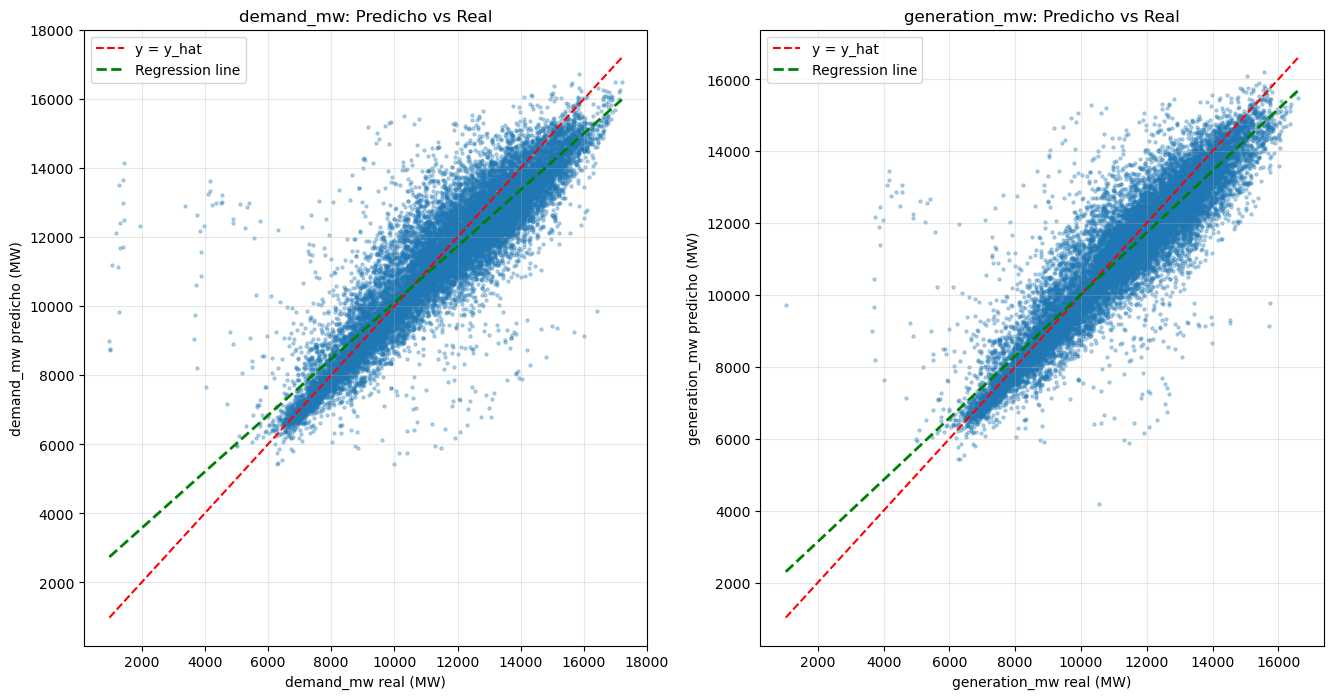

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, target in zip(axes, TARGETS):
    ax.scatter(test_set_y[target], y_pred[target], alpha=0.3, s=5)

    min_val = min(test_set_y[target].min(), y_pred[target].min())
    max_val = max(test_set_y[target].max(), y_pred[target].max())
    ax.plot([min_val, max_val], [min_val, max_val], "r--", label="y = y_hat")

    m, b = np.polyfit(test_set_y[target], y_pred[target], 1)
    x_line = np.linspace(min_val, max_val, 200)
    ax.plot(x_line, m * x_line + b, color="green", linestyle="--", linewidth=2, label="Regression line")

    ax.set_xlabel(f"{target} real (MW)")
    ax.set_ylabel(f"{target} predicho (MW)")
    ax.set_title(f"{target}: Predicho vs Real")
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()

# 14. Análisis de residuales
Calcule los residuales:

$$
e_i = y_i - \hat{y}_i
$$

Construya al menos una gráfica que permita analizar su comportamiento:

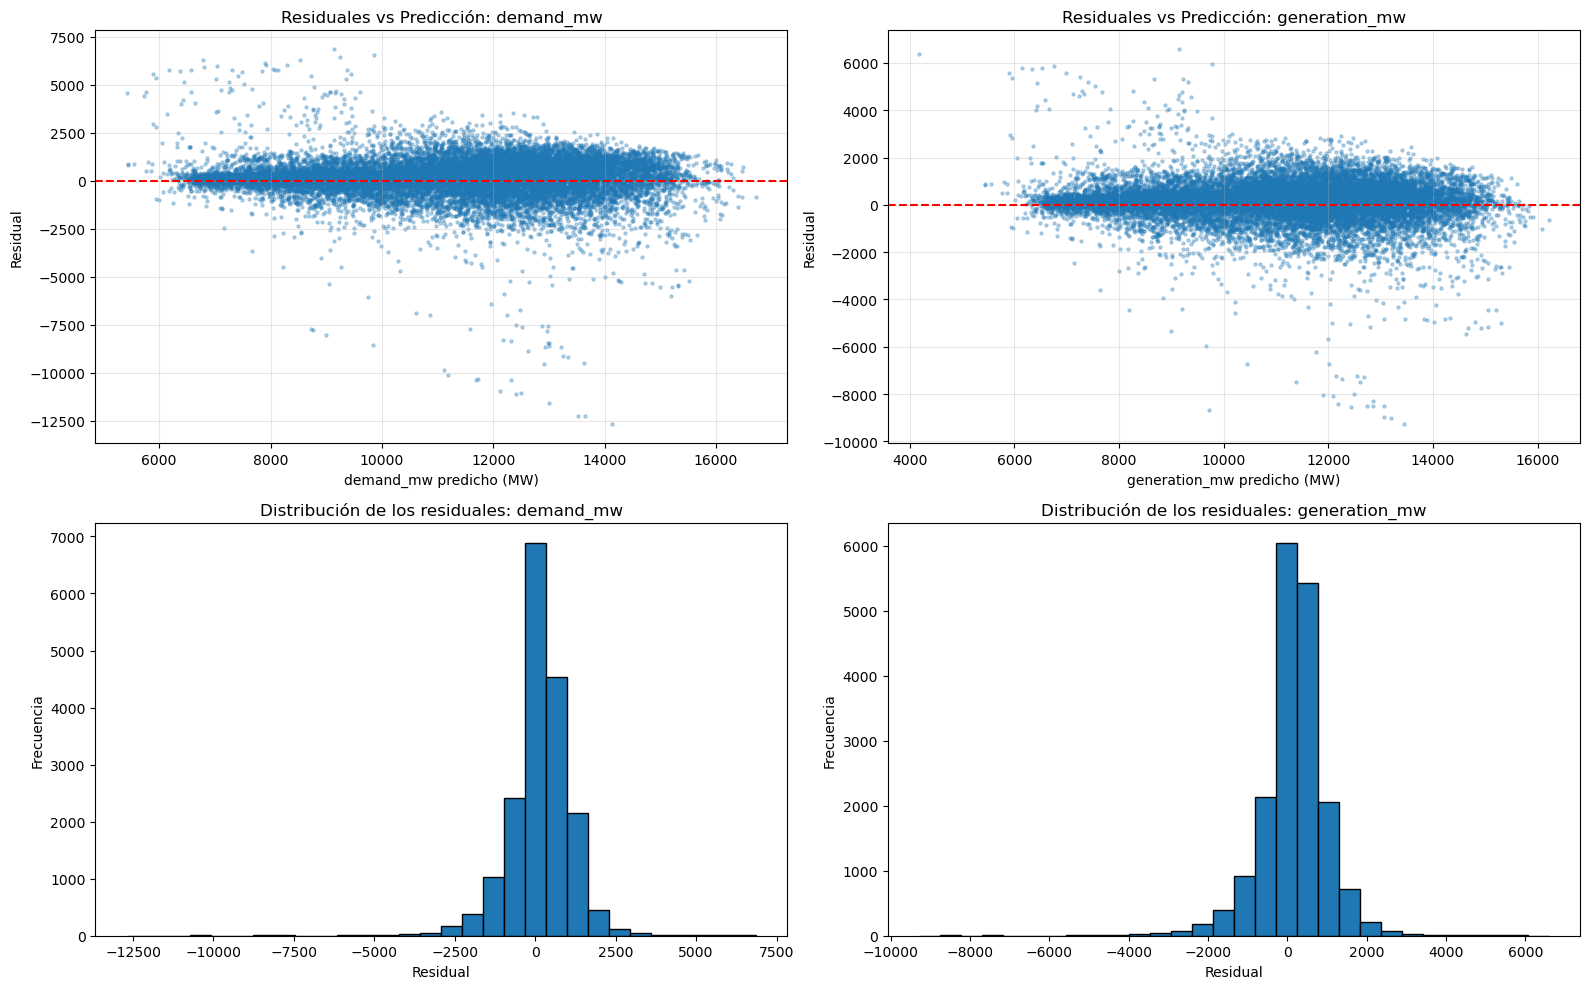

In [60]:
residuals = test_set_y - y_pred

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for col, target in enumerate(TARGETS):
    axes[0, col].scatter(y_pred[target], residuals[target], alpha=0.3, s=5)
    axes[0, col].axhline(0, color="red", linestyle="--")
    axes[0, col].set_title(f"Residuales vs Predicción: {target}")
    axes[0, col].set_xlabel(f"{target} predicho (MW)")
    axes[0, col].set_ylabel("Residual")
    axes[0, col].grid(alpha=0.3)

    axes[1, col].hist(residuals[target], bins=30, edgecolor='black')
    axes[1, col].set_title(f"Distribución de los residuales: {target}")
    axes[1, col].set_xlabel("Residual")
    axes[1, col].set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

### Preguntas

**¿Los residuales están aproximadamente centrados alrededor de cero?**

**¿Existe algún patrón visible en los residuales?**

**¿La dispersión aumenta conforme aumenta la predicción?**

**¿Existen residuales extremos?**

**¿Qué podría indicar la presencia de un patrón sistemático?**

**¿Qué evidencia proporcionan los residuales acerca de si el modelo lineal está capturando adecuadamente la estructura de los datos?**

**¿Qué transformación o característica adicional podría explorar para mejorar el modelo?**

# 16. Conclusiones